# Video Deepfake Detection: ResNeXt-50 + CBAM + BiLSTM (Celeb-DF v2)
Identity-wise split, cached face crops, best-checkpoint, AUC/F1 and occlusion-based XAI.
Set Accelerator = GPU before running.

In [5]:
!pip install -q --no-deps facenet-pytorch grad-cam ttach

import os, re, glob, random, time
import cv2, numpy as np, torch, torch.nn as nn, torch.optim as optim
import torchvision.models as models
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm
from torch.utils.data import Dataset, DataLoader
from facenet_pytorch import MTCNN
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score, confusion_matrix

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

def set_seed(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

mtcnn = MTCNN(image_size=224, margin=20, keep_all=False, post_process=False, device=device)

Device: cuda Tesla T4


## Step 1: Identity-wise split (no person appears in more than one split)

In [6]:
ROOT = "/kaggle/input/datasets/reubensuju/celeb-df-v2"
real = sorted(glob.glob(f"{ROOT}/Celeb-real/*.mp4"))
fake = sorted(glob.glob(f"{ROOT}/Celeb-synthesis/*.mp4"))
print("Total real:", len(real), "| Total fake:", len(fake))

def vid_ids(p):
    return re.findall(r"id\d+", os.path.basename(p))   # real: [id0]; fake: [id0, id16]

all_ids = sorted({i for p in real + fake for i in vid_ids(p)}, key=lambda s: int(s[2:]))
rng = random.Random(42)
rng.shuffle(all_ids)
n = len(all_ids)
val_ids  = set(all_ids[: n // 5])
test_ids = set(all_ids[n // 5 : 2 * n // 5])

def which(p):
    ids = set(vid_ids(p))
    if ids <= val_ids:               return "val"
    if ids <= test_ids:              return "test"
    if not (ids & (val_ids | test_ids)): return "train"
    return None                      # mixes identities across splits -> dropped

buckets = {s: {"real": [], "fake": []} for s in ["train", "val", "test"]}
for p in real:
    s = which(p)
    if s: buckets[s]["real"].append(p)
for p in fake:
    s = which(p)
    if s: buckets[s]["fake"].append(p)

data = {}
for s, b in buckets.items():
    rng.shuffle(b["fake"])
    b["fake"] = b["fake"][: len(b["real"])]            # balance fake = real
    data[s] = (b["real"] + b["fake"], [0] * len(b["real"]) + [1] * len(b["fake"]))
    print(f"{s:5s} real: {len(b['real']):4d} | fake: {len(b['fake']):4d}")

Total real: 590 | Total fake: 5639
train real:  364 | fake:  364
val   real:  111 | fake:  111
test  real:  115 | fake:  115


## Step 2: Cache 16 face crops per video (run once, ~25-30 min)

In [7]:
CACHE = "/kaggle/working/cache"
os.makedirs(CACHE, exist_ok=True)

def cache_path(p):
    return f"{CACHE}/{os.path.basename(os.path.dirname(p))}__{os.path.basename(p)[:-4]}.pt"

def extract_raw(video_path, num_frames=16):
    cap = cv2.VideoCapture(video_path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    idxs = np.linspace(0, max(total - 1, 0), num_frames, dtype=int)
    faces, missing = [], 0
    for i in idxs:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
        ok, frame = cap.read()
        f = None
        if ok:
            with torch.no_grad():
                f = mtcnn(Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)))
        if f is None:
            missing += 1
            f = faces[-1].clone() if faces else torch.zeros(3, 224, 224, dtype=torch.uint8)
        else:
            f = f.cpu().clamp(0, 255).byte()
        faces.append(f)
    cap.release()
    return torch.stack(faces), missing                  # uint8 (16,3,224,224)

missing_log = {}
for s in data:
    for p in tqdm(data[s][0], desc=f"cache {s}"):
        out = cache_path(p)
        if not os.path.exists(out):
            seq, miss = extract_raw(p)
            torch.save(seq, out)
            missing_log[p] = miss

bad = [p for p, m in missing_log.items() if m > 8]
print("Videos with >8/16 frames missing a face:", len(bad))

cache test: 100%|██████████| 230/230 [03:39<00:00,  1.05it/s]

Videos with >8/16 frames missing a face: 1


## Step 3: Dataset (reads cache, light augmentation) and DataLoaders

In [8]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

class CachedDataset(Dataset):
    def __init__(self, paths, labels, train=False):
        self.paths, self.labels, self.train = paths, labels, train
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        x = torch.load(cache_path(self.paths[i])).float() / 255.0     # (16,3,224,224)
        if self.train:
            if random.random() < 0.5:
                x = x.flip(-1)                                         # same flip for all frames
            x = x * (0.8 + 0.4 * random.random()) + (random.random() - 0.5) * 0.2
            x = x.clamp(0, 1)
        x = (x - MEAN) / STD
        return x, torch.tensor(self.labels[i], dtype=torch.float32)

def make_loader(split, train):
    return DataLoader(CachedDataset(*data[split], train=train), batch_size=4,
                      shuffle=train, num_workers=2)

train_loader, val_loader, test_loader = make_loader("train", True), make_loader("val", False), make_loader("test", False)
print("Batches -> train:", len(train_loader), "| val:", len(val_loader), "| test:", len(test_loader))

Batches -> train: 182 | val: 56 | test: 58


## Step 4: Model (ResNeXt-50 -> CBAM -> BiLSTM)

In [9]:
class ChannelAttention(nn.Module):
    def __init__(self, in_planes, ratio=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(in_planes, in_planes // ratio, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(in_planes // ratio, in_planes, 1, bias=False))
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        return x * self.sigmoid(self.fc(self.avg_pool(x)) + self.fc(self.max_pool(x)))

class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv1 = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        return x * self.sigmoid(self.conv1(torch.cat([avg_out, max_out], dim=1)))

class CBAM(nn.Module):
    def __init__(self, in_planes, ratio=16, kernel_size=7):
        super().__init__()
        self.ca = ChannelAttention(in_planes, ratio)
        self.sa = SpatialAttention(kernel_size)
    def forward(self, x):
        return self.sa(self.ca(x))

class VideoDeepfakeModel(nn.Module):
    def __init__(self, lstm_hidden=256):
        super().__init__()
        backbone = models.resnext50_32x4d(weights=models.ResNeXt50_32X4D_Weights.DEFAULT)
        self.cnn_backbone = nn.Sequential(*list(backbone.children())[:-2])
        self.cbam = CBAM(2048)
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.bilstm = nn.LSTM(2048, lstm_hidden, num_layers=1, batch_first=True, bidirectional=True)
        self.frame_attention = nn.Linear(lstm_hidden * 2, 1)
        self.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(lstm_hidden * 2, 1))

    def forward(self, x):                                   # (B, T, 3, 224, 224)
        b, t, c, h, w = x.shape
        feat = self.cnn_backbone(x.view(b * t, c, h, w))
        pooled = self.global_pool(self.cbam(feat)).view(b, t, -1)
        lstm_out, _ = self.bilstm(pooled)
        att = torch.softmax(self.frame_attention(lstm_out), dim=1)
        video_repr = torch.sum(lstm_out * att, dim=1)
        return self.classifier(video_repr), att.squeeze(-1)

print("Model defined.")

Model defined.


## Step 5: Training (best checkpoint by val AUC, early stopping, AMP)

In [10]:
set_seed()
use_amp = device.type == "cuda"
model = VideoDeepfakeModel().to(device)

backbone_params = list(model.cnn_backbone.parameters())
head_params = [p for n, p in model.named_parameters() if not n.startswith("cnn_backbone")]
optimizer = optim.AdamW([{"params": backbone_params, "lr": 1e-5},
                         {"params": head_params, "lr": 1e-4}], weight_decay=1e-4)
EPOCHS = 12
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
criterion = nn.BCEWithLogitsLoss()
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

def evaluate(loader):
    model.eval()
    ys, ps, tot = [], [], 0.0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device).unsqueeze(1)
            with torch.autocast("cuda", enabled=use_amp):
                logits, _ = model(x)
            tot += criterion(logits.float(), y).item()
            ps += torch.sigmoid(logits.float()).squeeze(1).cpu().tolist()
            ys += y.squeeze(1).cpu().tolist()
    ys, ps = np.array(ys), np.array(ps)
    preds = (ps > 0.5).astype(int)
    return {"loss": tot / len(loader), "auc": roc_auc_score(ys, ps), "acc": float((preds == ys).mean()),
            "f1": f1_score(ys, preds), "prec": precision_score(ys, preds),
            "rec": recall_score(ys, preds), "cm": confusion_matrix(ys, preds)}

best_auc, patience, bad_epochs = 0.0, 4, 0
history = []
for epoch in range(EPOCHS):
    model.train()
    t0, run = time.time(), 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device).unsqueeze(1)
        optimizer.zero_grad()
        with torch.autocast("cuda", enabled=use_amp):
            logits, _ = model(x)
        loss = criterion(logits.float(), y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        run += loss.item()
    scheduler.step()
    v = evaluate(val_loader)
    history.append((run / len(train_loader), v["loss"], v["auc"]))
    print(f"Ep {epoch+1:2d} | {time.time()-t0:4.0f}s | train {run/len(train_loader):.4f} | "
          f"val loss {v['loss']:.4f} auc {v['auc']:.3f} acc {v['acc']:.3f} f1 {v['f1']:.3f}")
    if v["auc"] > best_auc:
        best_auc, bad_epochs = v["auc"], 0
        torch.save(model.state_dict(), "best_video_model.pth")
        print("   saved best model")
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            print("Early stopping.")
            break

Downloading: "https://download.pytorch.org/models/resnext50_32x4d-1a0047aa.pth" to /root/.cache/torch/hub/checkpoints/resnext50_32x4d-1a0047aa.pth


100%|██████████| 95.8M/95.8M [00:00<00:00, 128MB/s] 


Ep  1 |   79s | train 0.6723 | val loss 0.5251 auc 0.917 acc 0.806 f1 0.790
   saved best model
Ep  2 |   77s | train 0.4591 | val loss 0.3269 auc 0.961 acc 0.869 f1 0.857
   saved best model
Ep  3 |   77s | train 0.3147 | val loss 0.2866 auc 0.974 acc 0.883 f1 0.870
   saved best model
Ep  4 |   76s | train 0.2130 | val loss 0.2043 auc 0.976 acc 0.910 f1 0.913
   saved best model
Ep  5 |   76s | train 0.2346 | val loss 0.2165 auc 0.977 acc 0.928 f1 0.926
   saved best model
Ep  6 |   77s | train 0.1904 | val loss 0.2078 auc 0.977 acc 0.919 f1 0.917
   saved best model
Ep  7 |   76s | train 0.1654 | val loss 0.2015 auc 0.978 acc 0.914 f1 0.915
   saved best model
Ep  8 |   77s | train 0.2047 | val loss 0.2098 auc 0.977 acc 0.914 f1 0.917
Ep  9 |   77s | train 0.1317 | val loss 0.2094 auc 0.977 acc 0.919 f1 0.918
Ep 10 |   76s | train 0.1416 | val loss 0.2035 auc 0.976 acc 0.923 f1 0.923
Ep 11 |   77s | train 0.1651 | val loss 0.2270 auc 0.973 acc 0.910 f1 0.912
Early stopping.


## Step 6: Final test evaluation (run once, report these numbers)

In [11]:
model.load_state_dict(torch.load("best_video_model.pth", map_location=device))
t = evaluate(test_loader)
print(f"TEST  AUC {t['auc']:.4f} | Acc {t['acc']:.4f} | F1 {t['f1']:.4f} | "
      f"Precision {t['prec']:.4f} | Recall {t['rec']:.4f}")
print("Confusion matrix [rows = true real/fake, cols = pred real/fake]:\n", t["cm"])

TEST  AUC 0.9801 | Acc 0.9261 | F1 0.9231 | Precision 0.9623 | Recall 0.8870
Confusion matrix [rows = true real/fake, cols = pred real/fake]:
 [[111   4]
 [ 13 102]]


## Step 7: Explainability (occlusion frame influence + Grad-CAM)

id32_id33_0001.mp4 | FAKE | fake prob 96.0% | most influential frame #9


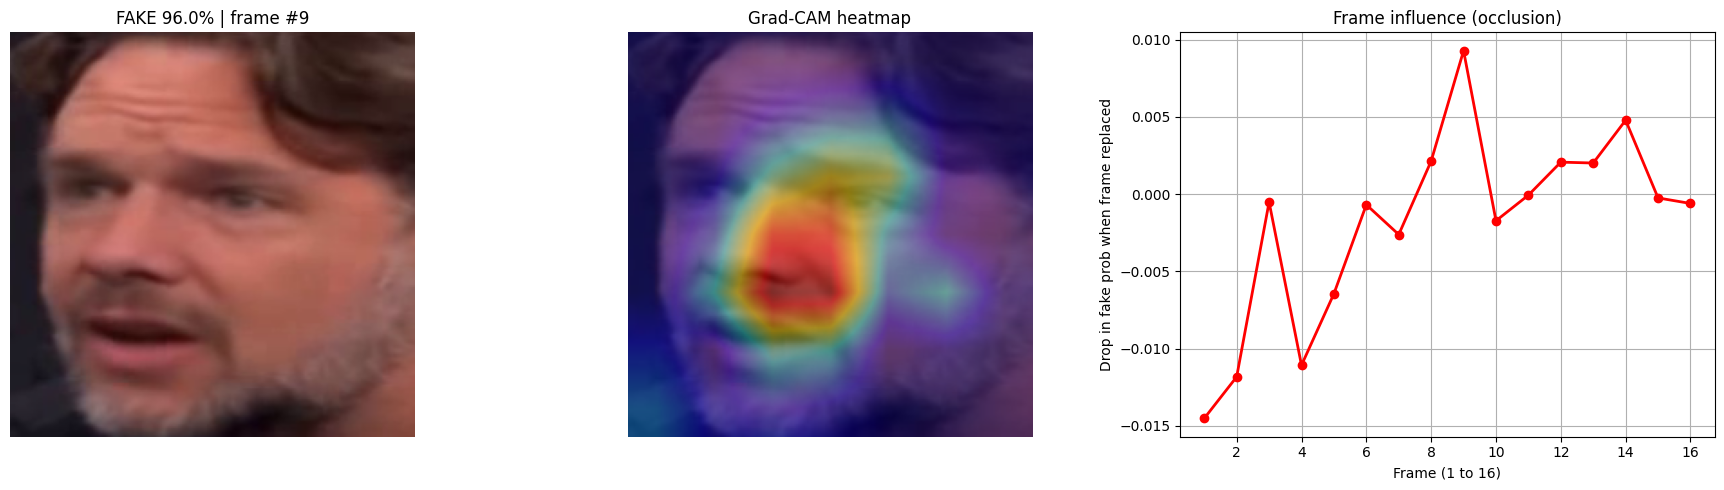

id10_0000.mp4 | REAL | fake prob 0.4% | most influential frame #11


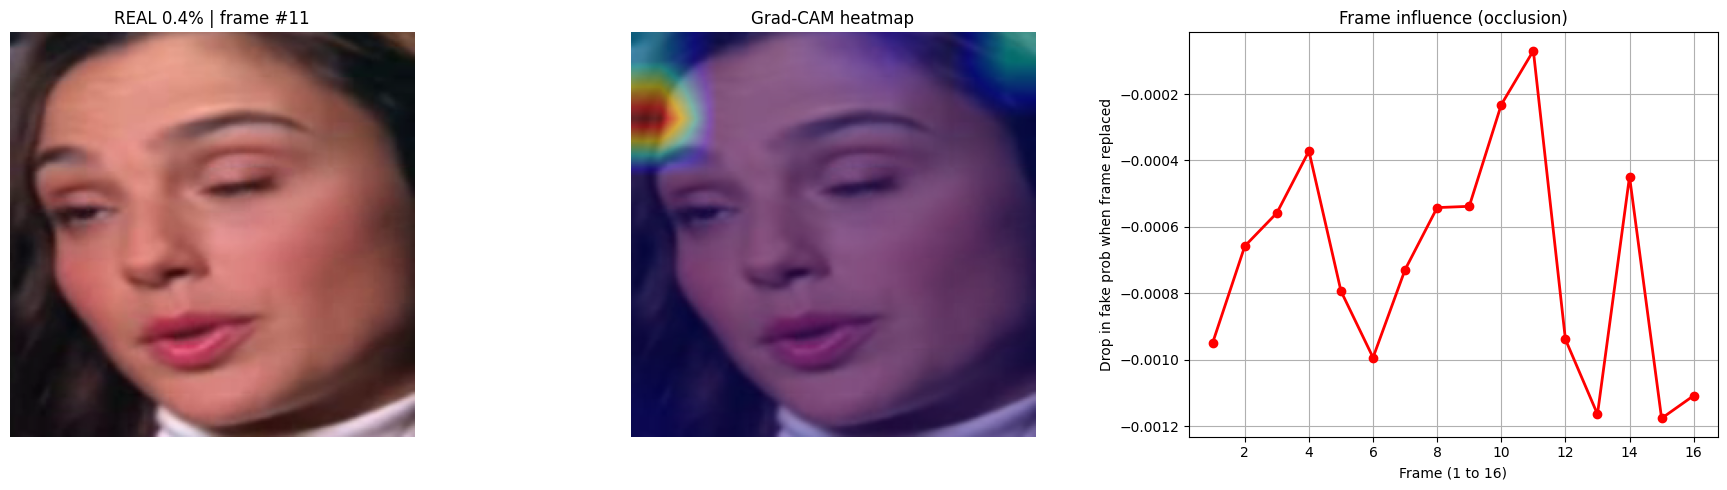

In [14]:
@torch.no_grad()
def frame_importance(model, x):
    model.eval()
    base = torch.sigmoid(model(x)[0]).item()
    mean_frame = x.mean(dim=1)
    imp = []
    for t_ in range(x.shape[1]):
        xo = x.clone()
        xo[:, t_] = mean_frame
        imp.append(base - torch.sigmoid(model(xo)[0]).item())
    return base, np.array(imp)

def explain(video_path):
    model.eval()
    seq = (torch.load(cache_path(video_path)).float() / 255.0 - MEAN) / STD      # (16,3,224,224)
    x = seq.unsqueeze(0).to(device)

    base, imp = frame_importance(model, x)                  # before hooks
    idx = int(np.argmax(imp))      # most positive = frame that pushes towards FAKE
    verdict = "FAKE" if base > 0.5 else "REAL"
    print(f"{os.path.basename(video_path)} | {verdict} | fake prob {base*100:.1f}% | most influential frame #{idx+1}")

    acts, grads = {}, {}
    layer = model.cnn_backbone[-1]
    h1 = layer.register_forward_hook(lambda m, i, o: acts.__setitem__("a", o))
    h2 = layer.register_full_backward_hook(lambda m, gi, go: grads.__setitem__("g", go[0]))
    x.requires_grad_(True)
    torch.backends.cudnn.enabled = False                    # needed for LSTM backward in eval mode
    logits, _ = model(x)
    model.zero_grad()
    logits[0, 0].backward()
    torch.backends.cudnn.enabled = True
    h1.remove(); h2.remove()

    act, grad = acts["a"][idx].detach().cpu(), grads["g"][idx].detach().cpu()
    w = grad.mean(dim=(1, 2), keepdim=True)
    cam = torch.relu((w * act).sum(0)).numpy()
    cam = cv2.resize(cam, (224, 224))
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    heat = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB) / 255.0
    face = np.clip(seq[idx].numpy().transpose(1, 2, 0) * np.array([0.229, 0.224, 0.225])
                   + np.array([0.485, 0.456, 0.406]), 0, 1)
    overlay = np.clip(0.4 * heat + 0.6 * face, 0, 1)

    fig, ax = plt.subplots(1, 3, figsize=(18, 5))
    ax[0].imshow(face);    ax[0].set_title(f"{verdict} {base*100:.1f}% | frame #{idx+1}"); ax[0].axis("off")
    ax[1].imshow(overlay); ax[1].set_title("Grad-CAM heatmap");                           ax[1].axis("off")
    ax[2].plot(range(1, 17), imp, marker="o", color="red", linewidth=2)
    ax[2].set_title("Frame influence (occlusion)")
    ax[2].set_xlabel("Frame (1 to 16)"); ax[2].set_ylabel("Drop in fake prob when frame replaced")
    ax[2].grid(True)
    plt.tight_layout(); plt.show()

# test videos only, never training videos
explain(buckets["test"]["fake"][0])
explain(buckets["test"]["real"][0])

## Step 8: Find a wrong prediction for the report (failure case)

Wrong test predictions: 16 of 230
id45_0001.mp4 | true: real | pred fake prob: 0.59
id4_0009.mp4 | true: real | pred fake prob: 0.91
id52_0000.mp4 | true: real | pred fake prob: 0.59
id52_0009.mp4 | true: real | pred fake prob: 0.61
id33_id32_0005.mp4 | true: fake | pred fake prob: 0.40
id45_0001.mp4 | FAKE | fake prob 59.1% | most influential frame #2


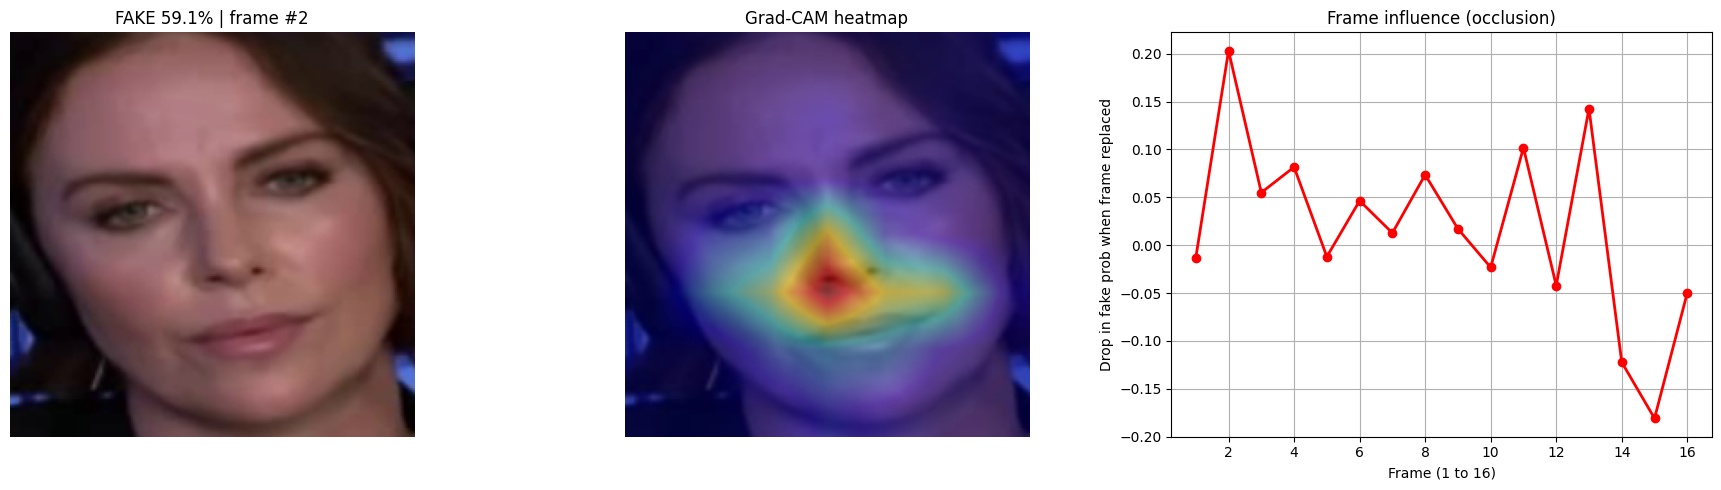

In [13]:
model.eval()
wrong = []
with torch.no_grad():
    for p, y in zip(*data["test"]):
        seq = (torch.load(cache_path(p)).float() / 255.0 - MEAN) / STD
        prob = torch.sigmoid(model(seq.unsqueeze(0).to(device))[0]).item()
        if int(prob > 0.5) != y:
            wrong.append((p, y, prob))
print("Wrong test predictions:", len(wrong), "of", len(data["test"][0]))
for p, y, prob in wrong[:5]:
    print(os.path.basename(p), "| true:", "fake" if y else "real", "| pred fake prob:", f"{prob:.2f}")
if wrong:
    explain(wrong[0][0])